Week 6 notebook, decision trees and random forests, Mike Hembree

Last technique. Same classification problem as Weeks 4 and 5, whether a stay in the MIMIC-IV demo table (140 stays, 45 positive) ever gets a positive delirium screen. Trees are a nice contrast to everything before this because they don't care about feature scale and they can pick up nonlinear effects and interactions without me having to build them by hand like in Week 1.

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split, RepeatedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, roc_auc_score, roc_curve, f1_score, recall_score, precision_score, accuracy_score, confusion_matrix

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'serif'


In [2]:
# load the feature table and fill the few missing values with the median
feat = pd.read_csv('delirium_features.csv')

rcols = ['anchor_age', 'gender', 'heart_rate', 'sbp', 'dbp', 'resp_rate', 'temp_f', 'spo2', 'gcs_total_min', 'delirium_positive']
ccols = rcols[:-1]

data = feat[rcols + ['los']].copy()
for c in rcols:
    data[c] = data[c].fillna(data[c].median())

X = data[rcols]
y = data['los']
Xc = data[ccols]
yc = feat['delirium_positive'].fillna(0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size = 0.2, random_state = 42, stratify = yc)

cv_reg = RepeatedKFold(n_splits = 5, n_repeats = 6, random_state = 1)
cv_clf = RepeatedStratifiedKFold(n_splits = 5, n_repeats = 3, random_state = 1)
print(data.shape, yc.value_counts().to_dict())


(140, 11) {0: 95, 1: 45}


In [3]:
# single decision tree, depth sweep with training auc against cv auc
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import validation_curve

depths = [1, 2, 3, 4, 5, 6, 8, 10, None]
rows = []
for d in depths:
    r = cross_validate(DecisionTreeClassifier(max_depth = d, class_weight = 'balanced', random_state = 0), Xc, yc, cv = cv_clf, scoring = 'roc_auc', return_train_score = True, n_jobs = 2)
    rows.append({'max depth': 'none' if d is None else d, 'train auc': r['train_score'].mean(), 'cv auc': r['test_score'].mean()})
tree_depth = pd.DataFrame(rows)
tree_depth.round(3)


,max depth,train auc,cv auc
0,1,0.740,0.690
1,2,0.808,0.689
2,3,0.877,0.700
3,4,0.923,0.713
4,5,0.955,0.690
5,6,0.974,0.671
6,8,0.993,0.633
7,10,0.999,0.611
8,none,1.000,0.620


This is the overfitting picture I wanted. Training auc climbs from 0.74 at depth 1 to 1.00 with no limit, while cross validated auc peaks at 0.71 around depth 4 and then falls to about 0.61 to 0.62 for deep trees. The unrestricted tree memorizes the 140 stays.

holdout auc: 0.716


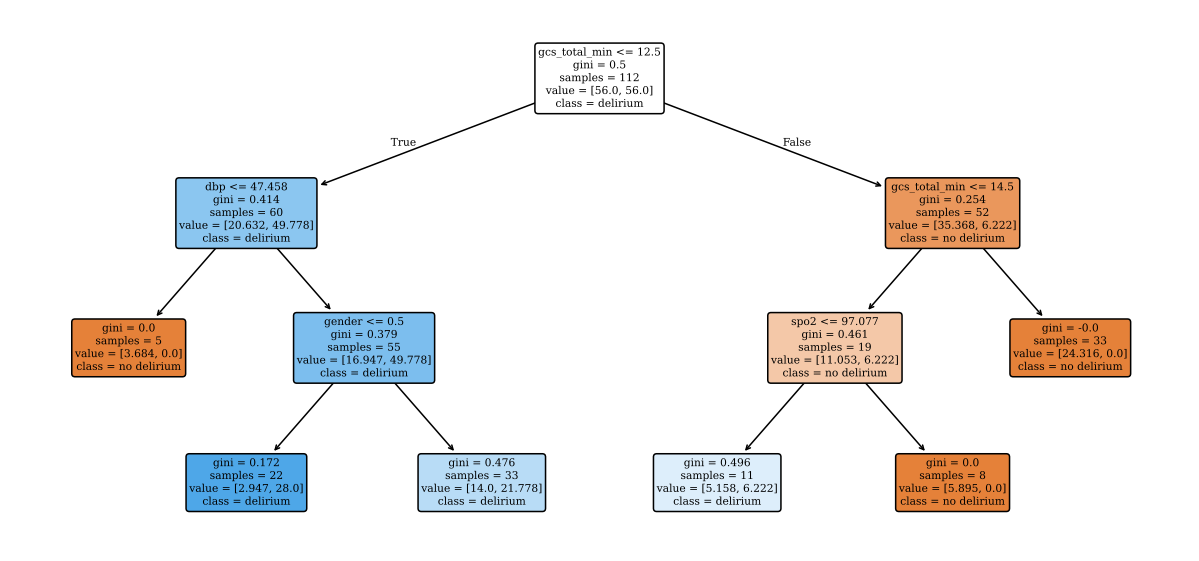

In [4]:
# a shallow tree on the holdout split to look at the splits
t = DecisionTreeClassifier(max_depth = 3, min_samples_leaf = 5, class_weight = 'balanced', random_state = 0).fit(Xc_train, yc_train)
print('holdout auc:', round(roc_auc_score(yc_test, t.predict_proba(Xc_test)[:, 1]), 3))
fig, ax = plt.subplots(figsize = (11, 5.2))
plot_tree(t, feature_names = ccols, class_names = ['no delirium', 'delirium'], filled = True, rounded = True, fontsize = 7, ax = ax)
plt.tight_layout()
plt.savefig('figs/tree.png', dpi = 200)
plt.show()


In [5]:
# random forest, holdout split and a small grid search on the training rows
from sklearn.ensemble import RandomForestClassifier

rf0 = RandomForestClassifier(n_estimators = 300, random_state = 0).fit(Xc_train, yc_train)
print('default rf holdout auc:', round(roc_auc_score(yc_test, rf0.predict_proba(Xc_test)[:, 1]), 3))

grid = {'max_depth': [3, 5, None], 'min_samples_leaf': [1, 3, 5], 'max_features': ['sqrt', 0.5]}
gs = GridSearchCV(RandomForestClassifier(n_estimators = 300, class_weight = 'balanced', random_state = 0), grid, scoring = 'roc_auc', cv = 5, n_jobs = 2)
gs.fit(Xc_train, yc_train)
print(gs.best_params_, round(gs.best_score_, 3))
best_rf = gs.best_estimator_
print('tuned rf holdout auc:', round(roc_auc_score(yc_test, best_rf.predict_proba(Xc_test)[:, 1]), 3))
pd.DataFrame(gs.cv_results_)[['param_max_depth', 'param_min_samples_leaf', 'param_max_features', 'mean_test_score']].sort_values('mean_test_score', ascending = False).head(8).round(3)


default rf holdout auc: 0.854


{'max_depth': 3, 'max_features': 0.5, 'min_samples_leaf': 3} 0.806
tuned rf holdout auc: 0.86


,param_max_depth,param_min_samples_leaf,param_max_features,mean_test_score
4,3,3,0.5,0.806
3,3,1,0.5,0.803
5,3,5,0.5,0.803
6,5,1,sqrt,0.802
10,5,3,0.5,0.795
0,3,1,sqrt,0.794
9,5,1,0.5,0.794
1,3,3,sqrt,0.794


The default forest scores an auc of 0.85 on the holdout split and the tuned one 0.86. The grid search preferred shallow trees (max depth 3), leaves of at least 3 stays, and looking at half the features at each split, with a cv auc of 0.806 on the training rows. Shallow and heavily averaged trees makes sense given how little data there is.

In [6]:
# nested cross validation, tuning inside every outer fold, all tree models
scoring = ('roc_auc', 'recall', 'precision', 'f1', 'accuracy')
tree_gs = GridSearchCV(DecisionTreeClassifier(class_weight = 'balanced', random_state = 0), {'max_depth': [2, 3, 4, 5, 6], 'min_samples_leaf': [1, 3, 5, 10]}, scoring = 'roc_auc', cv = 5)
rf_gs = GridSearchCV(RandomForestClassifier(n_estimators = 300, class_weight = 'balanced', random_state = 0), grid, scoring = 'roc_auc', cv = 5)
rows = []
for name, m in [('decision tree tuned', tree_gs), ('random forest default', RandomForestClassifier(n_estimators = 300, random_state = 0)), ('random forest tuned', rf_gs)]:
    r = cross_validate(m, Xc, yc, cv = cv_clf, scoring = scoring, n_jobs = 2)
    rows.append({'model': name, 'auc': r['test_roc_auc'].mean(), 'auc sd': r['test_roc_auc'].std(), 'recall': r['test_recall'].mean(), 'precision': r['test_precision'].mean(), 'f1': r['test_f1'].mean(), 'accuracy': r['test_accuracy'].mean()})
tree_res = pd.DataFrame(rows)
tree_res.to_csv('figs/tree_results.csv', index = False)
tree_res.round(3)


,model,auc,auc sd,recall,precision,f1,accuracy
0,decision tree tuned,0.753,0.083,0.763,0.539,0.622,0.700
1,random forest default,0.779,0.106,0.519,0.650,0.563,0.743
2,random forest tuned,0.793,0.089,0.763,0.514,0.609,0.693


Nested cross validation says the tuned forest has an auc of 0.793, the default forest 0.779 and the tuned single tree 0.753. The forest is on top, but the fold to fold standard deviations are around 0.09 to 0.10, so the gap to the other models is small compared with the noise. The default forest has the best precision and accuracy but only 0.52 recall, and tuning with balanced class weights moves recall up to 0.76.

In [7]:
# feature importance, impurity based and permutation based on out of fold stays
from sklearn.inspection import permutation_importance
from sklearn.model_selection import StratifiedKFold

final = RandomForestClassifier(n_estimators = 500, max_depth = gs.best_params_['max_depth'], min_samples_leaf = gs.best_params_['min_samples_leaf'], max_features = gs.best_params_['max_features'], class_weight = 'balanced', random_state = 0)
imp = pd.Series(final.fit(Xc, yc).feature_importances_, index = ccols)
perm = []
for tr, te in StratifiedKFold(5, shuffle = True, random_state = 3).split(Xc, yc):
    f = RandomForestClassifier(n_estimators = 500, max_depth = gs.best_params_['max_depth'], min_samples_leaf = gs.best_params_['min_samples_leaf'], max_features = gs.best_params_['max_features'], class_weight = 'balanced', random_state = 0).fit(Xc.iloc[tr], yc.iloc[tr])
    p = permutation_importance(f, Xc.iloc[te], yc.iloc[te], scoring = 'roc_auc', n_repeats = 20, random_state = 0)
    perm.append(p.importances_mean)
perm = pd.Series(np.mean(perm, axis = 0), index = ccols)
imp_tab = pd.DataFrame({'impurity': imp, 'permutation auc drop': perm}).sort_values('impurity', ascending = False)
imp_tab.to_csv('figs/rf_importance.csv')
imp_tab.round(3)


,impurity,permutation auc drop
gcs_total_min,0.459,0.237
temp_f,0.145,0.053
spo2,0.099,0.004
anchor_age,0.072,0.002
resp_rate,0.066,0.019
dbp,0.057,0.002
heart_rate,0.042,-0.004
sbp,0.041,-0.000
gender,0.019,0.008


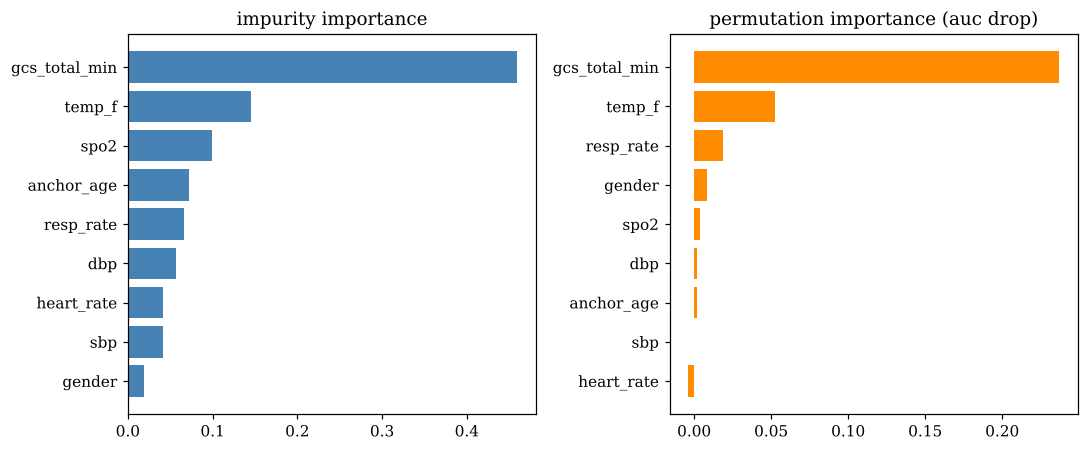

In [8]:
# figure, feature importance
fig, ax = plt.subplots(1, 2, figsize = (10, 4.2))
s = imp_tab.sort_values('impurity')
ax[0].barh(s.index, s['impurity'], color = 'steelblue')
ax[0].set_title('impurity importance')
s = imp_tab.sort_values('permutation auc drop')
ax[1].barh(s.index, s['permutation auc drop'], color = 'darkorange')
ax[1].set_title('permutation importance (auc drop)')
plt.tight_layout()
plt.savefig('figs/rf_importance.png', dpi = 200)
plt.show()


gcs_total_min dominates both importance measures (0.46 impurity, and shuffling it costs about 0.24 auc). temp_f is a distant second and a few variables are at zero or slightly negative, which means shuffling them doesn't hurt, so the forest isn't using them for anything that generalizes.